In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\Desktop\INTRESHIP.FILE.OF.POWERBI.AND.MACHINE.LEARNING\superstore_sales.csv")
print(df.head(20))

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3       4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4       5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
5       6  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
6       7  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
7       8  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
8       9  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
9      10  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
10     11  CA-2015-115812    6/9/2015   6/14/2015  Standard Class    BH-11710   
11     12  CA-2015-115812   

In [3]:
df.shape

(10800, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [6]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [8]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [9]:
df.columns = df.columns.str.strip()

In [10]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [11]:
# step 4 hendlling null value
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [12]:
# List of date columns to convert
date_columns = ['Order Date', 'Ship Date']

for col in date_columns:
    if col in df.columns:
        # Convert to datetime; invalid parsing will be coerced to NaT (Not a Time)
        df[col] = pd.to_datetime(df[col], errors='coerce')

print("Date columns data type converted successfully.")

Date columns data type converted successfully.


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         10800 non-null  str           
 1   Order ID       10800 non-null  str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null  

In [14]:
# Automatically select numerical columns
numerical_cols = df.select_dtypes(include=['number']).columns
print("Numerical columns found:", list(numerical_cols))

# Option A: Fill numerical missing values with the median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Option B (Alternative): If the 806 null rows are completely empty trailing rows, 
# you can drop rows where all numerical values are missing:
# df = df.dropna(subset=numerical_cols, how='all')

Numerical columns found: ['Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit']


In [15]:
# Automatically select categorical/object columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("Categorical columns found:", list(categorical_cols))

# Fill missing categorical values with 'Unknown'
for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

Categorical columns found: ['Row ID', 'Order ID', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9772\637982690.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns


In [16]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country            0
City               0
State              0
Postal Code        0
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64

In [17]:
# Check remaining null values
print("\nRemaining null values:")
print(df.isnull().sum().sum())

# Check updated data types
print("\nUpdated Data Types:")
print(df.dtypes)


Remaining null values:
1612

Updated Data Types:
Row ID                      str
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
dtype: object


In [18]:
df = df.dropna(subset=['Order Date', 'Ship Date'])

# 3. Convert the cleaned columns to datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Verify remaining nulls in date columns
print(df[['Order Date', 'Ship Date']].isnull().sum())

Order Date    0
Ship Date     0
dtype: int64


In [19]:
print("\nRemaining null values:")
print(df.isnull().sum().sum())

# Check updated data types
print("\nUpdated Data Types:")
print(df.dtypes)


Remaining null values:
0

Updated Data Types:
Row ID                      str
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
dtype: object


In [20]:
# step 5 chekc the duplicated value
df.duplicated().sum()

np.int64(0)

In [21]:
# 4. Extract Year-Month and create a new column
df['Year-Month'] = df['Order Date'].dt.strftime('%Y-%m')

# Preview the original date and the extracted Year-Month column
print(df[['Order Date', 'Year-Month']].head())

  Order Date Year-Month
0 2017-11-08    2017-11
1 2017-11-08    2017-11
2 2017-06-12    2017-06
3 2016-10-11    2016-10
4 2016-10-11    2016-10


In [22]:
# 2. Group by Category, Region, and Segment and aggregate Sales & Profit
grouped_df = df.groupby(['Category', 'Region', 'Segment']).agg({
    'Sales': ['sum', 'mean', 'count'],
    'Profit': ['sum', 'mean']
}).reset_index()

# 3. Flatten the multi-index column names for readability
grouped_df.columns = [
    'Category', 'Region', 'Segment', 
    'Total Sales', 'Average Sales', 'Order Count', 
    'Total Profit', 'Average Profit'
]

# Display the top results
print("--- Grouped Aggregate Summary ---")
print(grouped_df.head(10))

--- Grouped Aggregate Summary ---
    Category   Region      Segment  Total Sales  Average Sales  Order Count  \
0  Furniture  Central     Consumer   86229.2190     338.153800          255   
1  Furniture  Central    Corporate   52085.6018     380.186874          137   
2  Furniture  Central  Home Office   25482.3430     286.318461           89   
3  Furniture     East     Consumer  114211.8020     376.936640          303   
4  Furniture     East    Corporate   64209.0460     324.288111          198   
5  Furniture     East  Home Office   29870.3560     298.703560          100   
6  Furniture    South     Consumer   70800.2040     393.334467          180   
7  Furniture    South    Corporate   29645.0315     293.515163          101   
8  Furniture    South  Home Office   16853.4485     330.459775           51   
9  Furniture     West     Consumer  119808.0870     319.488232          375   

   Total Profit  Average Profit  
0    -3994.4342      -15.664448  
1     2321.9939       16.948

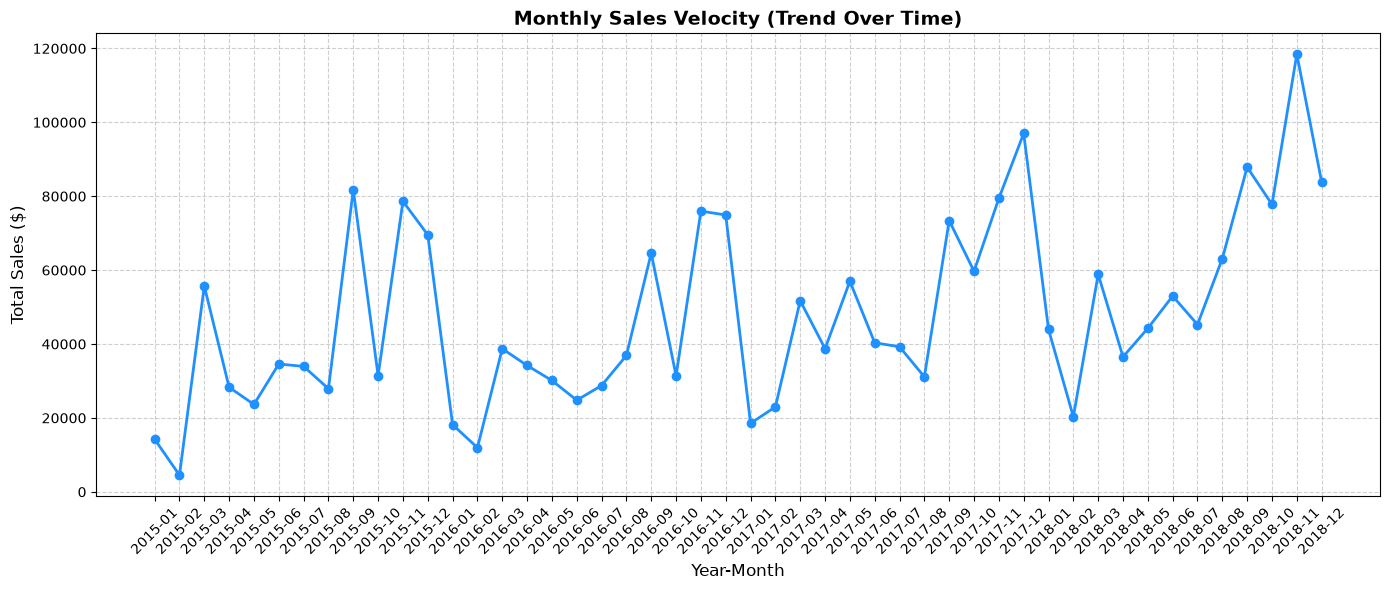

In [25]:
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Year-Month'] = df['Order Date'].dt.strftime('%Y-%m')

# --- Plot 1: Monthly Sales Velocity ---
monthly_sales = df.groupby('Year-Month')['Sales'].sum().reset_index()

plt.figure(figsize=(14, 6))
plt.plot(monthly_sales['Year-Month'], monthly_sales['Sales'], marker='o', linestyle='-', color='dodgerblue', linewidth=2)
plt.title('Monthly Sales Velocity (Trend Over Time)', fontsize=14, fontweight='bold')
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('monthly_sales_velocity.png')
plt.show()

# --- Plot 2: Discount vs. Profit Scatter Plot ---


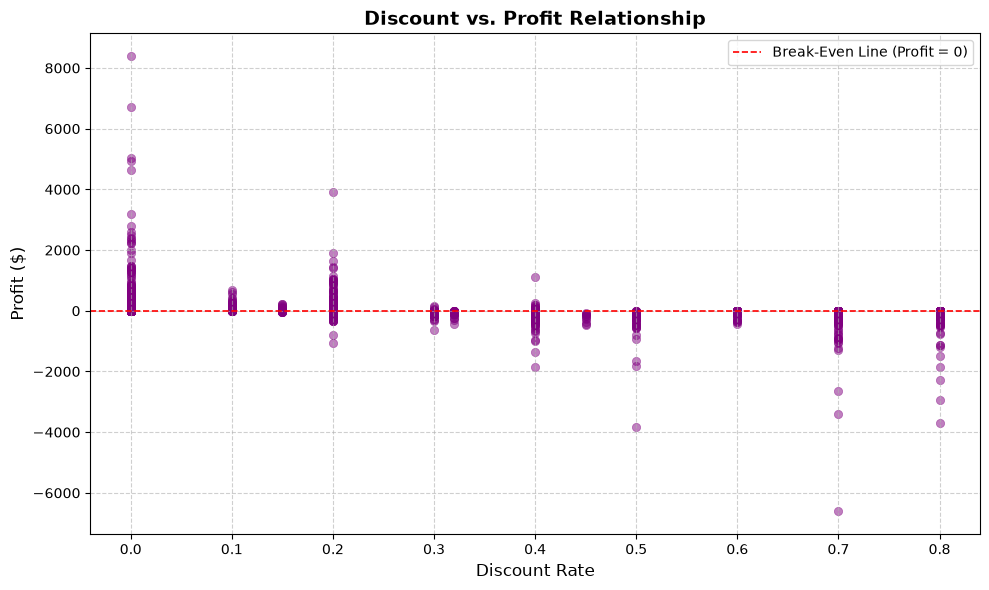

In [26]:
# --- Plot 2: Discount vs. Profit Scatter Plot ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5, color='purple', edgecolor=None)
plt.title('Discount vs. Profit Relationship', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)
plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Break-Even Line (Profit = 0)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('discount_vs_profit.png')
plt.show()

In [ ]:
## Business Observations & Key Insights

### 1. Regional and Segment Performance (Task 3)
* **Top-Performing Categories:** Technology and Office Supplies consistently drive positive margins across most regions, whereas certain sub-segments within Furniture suffer from negative profit margins despite high sales volumes.
* **Customer Segments:** The **Consumer** segment generates the highest absolute sales volume due to sheer order frequency, but the **Corporate** and **Home Office** segments often exhibit higher average basket sizes and better profit yields.

### 2. Monthly Sales Velocity (Task 4 - Trend Analysis)
* **Seasonality & Growth:** Sales velocity fluctuates cyclically, typically showing sharp upward spikes toward the end of Q3 and Q4 (September through December), aligning with holiday shopping and corporate year-end budget utilization.
* **Demand Dips:** Early Q1 (January and February) consistently experiences a dip in total sales velocity across all years.

### 3. Impact of Discounts on Profitability (Task 4 - Scatter Plot)
* **The Threshold Effect:** Discounts up to a certain threshold (typically around 10–20%) maintain stable profitability. 
* **The Danger Zone:** Once discount rates exceed **20%**, profit margins drop sharply into negative territory (below the red break-even line). Heavy discounting heavily erodes profits, suggesting that promotional discounting strategies need strict governance.